# 2026 U.S. Senate Forecast — Configurable Model

Extension of `Sample Code/senate_midterm_model_SAMPLE.ipynb`. Same backbone (weighted polls → national environment → fundamentals prior → Bayesian update → correlated simulations), with every modeling assumption pulled into one `CONFIG` dictionary so it can be changed and swept.

**How to use**
1. Edit values in the `CONFIG` cell (each has a note on why the default was chosen).
2. *Run All*. The main forecast prints, then the sensitivity sweep re-runs the model once per value in `SWEEP_PARAMS`.
3. Outputs land in `Output/` at the repo root.

All margins are **Democrat (or credible independent) minus Republican**, in points. Positive = D ahead.

Defaults marked `TEAM TODO` are placeholders the team has not agreed on yet.

In [1]:
import copy                                   # deep-copy CONFIG for sweep runs
import json                                   # parse the VoteHub API response
import re                                     # normalize pollster names
import urllib.request                         # stdlib HTTP (no extra install needed)
from pathlib import Path                      # OS-independent file paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option("display.width", 200)           # wide tables print on one line
pd.set_option("display.max_columns", 40)      # show all columns in race tables

## CONFIG — every assumption lives here

Grouped by model stage. A sweep (bottom of notebook) changes one key at a time, so key names are referenced as strings in `SWEEP_PARAMS`.

In [ ]:
# Repo root: works whether the notebook is opened from Model/ or from the repo root
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()

CONFIG = {
    # ---------------- Files & run settings ----------------
    "DATA_DIR": REPO_ROOT / "Data",                      # shared data folder (read-only; we never edit these files)
    "OUT_DIR": REPO_ROOT / "Output",                     # results written here (created if missing)
    "LEANS_FILE": "leans_and_regions.csv",
    "POLLS_FILE": "Midterm_Polls.xlsx",
    "NATIONAL_FILE": "National_Polls.xlsx",
    "ELECTION_DAY": "2026-11-03",
    "AS_OF_DATE": None,          # None = today. Set e.g. "2026-10-01" to re-run the model as of a past date (polls after it are dropped)
    "N_SIMS": 10_000,            # sample's value; the considerations doc recommends 5,000+
    "SEED": 2026,                # fixed seed -> identical results on every run/machine

    # ---------------- Senate map & control rules ----------------
    # Party currently holding each seat on the 2026 ballot (35 = 33 Class II + FL/OH specials)
    "SEATS_UP": {
        "Alabama": "R", "Alaska": "R", "Arkansas": "R", "Florida": "R", "Idaho": "R",
        "Iowa": "R", "Kansas": "R", "Kentucky": "R", "Louisiana": "R", "Maine": "R",
        "Mississippi": "R", "Montana": "R", "Nebraska": "R", "North Carolina": "R",
        "Ohio": "R", "Oklahoma": "R", "South Carolina": "R", "South Dakota": "R",
        "Tennessee": "R", "Texas": "R", "West Virginia": "R", "Wyoming": "R",
        "Colorado": "D", "Delaware": "D", "Georgia": "D", "Illinois": "D",
        "Massachusetts": "D", "Michigan": "D", "Minnesota": "D", "New Hampshire": "D",
        "New Jersey": "D", "New Mexico": "D", "Oregon": "D", "Rhode Island": "D",
        "Virginia": "D",
    },
    "HOLDOVER_D": 34,            # D + caucusing independents NOT on the ballot (47 - 13 up)
    "HOLDOVER_R": 31,            # R not on the ballot (53 - 22 up)
    "VP_PARTY": "R",             # VP breaks 50-50 ties -> with "R", Democrats need 51
    "D_SEATS_FOR_CONTROL": None, # None = derive from VP_PARTY (51 or 50). Set 52 to force the "Fetterman bitch ass" view
    # Probability each named holdover D-caucus senator votes with R on organizing the chamber (simulated per run)
    "HOLDOVER_DEFECTION_PROB": {"Fetterman (PA)": 0.0},   # DEFAULT 0: sample says operate on 51 unless new data
    # Races where the "Dem%" column is an independent; value = P(independent caucuses with D if they win)
    "INDEPENDENT_CAUCUS_PROB_D": {"Nebraska": 0.8},       # sample author's 80% for Osborn

    # Incumbent status for the prior's incumbency bonus: "running", "appointed" (appointed incumbent on ballot), "open".
    # Hand-maintained (no stable free API for this) — verified against news reports on 2026-10-15; re-check before final run.
    "INCUMBENT_STATUS": {
        # Open seats — retirements, lost primaries, appointees barred from running
        "Illinois": "open", "Michigan": "open", "Minnesota": "open", "New Hampshire": "open",   # Durbin, Peters, Smith, Shaheen retired
        "Alabama": "open", "Iowa": "open", "Kentucky": "open", "Montana": "open",              # Tuberville (gov), Ernst, McConnell, Daines
        "North Carolina": "open", "Wyoming": "open",                                           # Tillis, Lummis retired
        "Oklahoma": "open",          # Mullin resigned; appointee Armstrong pledged not to run
        "Texas": "open",             # Cornyn lost the May runoff to Paxton
        "Louisiana": "open",         # Cassidy eliminated in the primary
        # Appointed incumbents on the ballot
        "Florida": "appointed",      # Moody (Rubio's seat)
        "Ohio": "appointed",         # Husted (Vance's seat)
        "South Carolina": "appointed",  # Darline Graham, appointed after Lindsey Graham's death; won GOP runoff
        # Everyone else defaults to "running" (see DEFAULT_INCUMBENT_STATUS)
    },
    "DEFAULT_INCUMBENT_STATUS": "running",

    # ---------------- Data cleaning (done in code; source files untouched) ----------------
    # Manual spelling fixes; anything else is matched case/punctuation-insensitively automatically
    "POLLSTER_NAME_FIXES": {
        "St. Pete Pols": "St. Pete Polls", "St.Pete Polls": "St. Pete Polls",
        "Cygnal Politial": "Cygnal", "Fabrizio, Lee, & Asspcoates": "Fabrizio, Lee & Associates",
        "Morning consult": "Morning Consult", "HarrixX/Harris Poll": "HarrisX/Harris Poll",
    },
    "MIN_SAMPLE_SIZE": 0,              # drop polls smaller than this (0 = keep all)
    "MAX_POLL_AGE_DAYS": None,         # drop polls older than this many days (None = keep all; recency weighting handles age)
    "BIGGER_FIELD_MISSING_AS": False,  # 7 rows have a blank Bigger_Field (all Co/Efficient generic-ballot rows); treat as head-to-head
    "DROP_EXACT_DUPLICATES": True,     # e.g. AlphaROC 10/01 appears twice, identical, in National_Polls
    "NAT_ZERO_SAMPLE_IMPUTE": 1000,    # Winston Group has SampleSize 0; impute instead of zero weight

    # ---------------- Multi-version polls (same pollster/state/date, e.g. H2H + full field) ----------------
    # "split"            : keep every version, divide weight by # versions so the survey counts once in total (DEFAULT)
    # "keep_all"         : sample's behavior — each version counts as a separate poll (double counts respondents)
    # "prefer_h2h"       : keep only head-to-head version(s) when one exists
    # "prefer_full_field": keep only full-field version(s) when one exists
    "POLL_VERSION_MODE": "split",
    "DROP_GENERIC_IF_CANDIDATE_VERSION": True,   # if a survey has both a generic and a named-candidate version, drop the generic

    # ---------------- Undecided / other voters ----------------
    # "Other" = 100 - Dem% - Rep%. Part of it is truly undecided; the rest sticks with third parties.
    "OTHER_TO_UNDECIDED_H2H": 1.0,        # head-to-head: all non-D/R is undecided (no other names offered)
    "OTHER_TO_UNDECIDED_FULL_FIELD": 0.5, # full field: assume half of "other" is real third-party support. TEAM TODO
    # How undecideds break: "ignore" (raw D-R, sample's behavior), "proportional" (break like decided voters),
    # "fixed_share" (D gets UNDECIDED_D_SHARE), "against_incumbent" (challenger gets UNDECIDED_CHALLENGER_SHARE; open seats split evenly)
    "UNDECIDED_MODE": "proportional",     # DEFAULT: neutral, equivalent to using two-party share
    "UNDECIDED_D_SHARE": 0.5,             # used only by "fixed_share"
    "UNDECIDED_CHALLENGER_SHARE": 0.55,   # used only by "against_incumbent"; classic "incumbent rule" is weak in modern data -> modest 55%
    "UNDECIDED_SPLIT_SD": 0.15,           # uncertainty in the fraction of undecideds going D; adds 2*U*SD points of margin SD to each race

    # ---------------- Poll weights ----------------
    "RECENCY_HALF_LIFE_DAYS": 21,     # sample author's suggestion: after ~3 weeks a poll is half as informative
    "REFERENCE_SAMPLE": 800,          # median sample size in our data -> a typical poll gets size weight 1.0
    "SAMPLE_SIZE_EXPONENT": 0.5,      # weight ∝ (n/ref)^0.5 (sampling error shrinks with sqrt n)
    "SAMPLE_SIZE_CAP": 2500,          # n above this gets no extra weight; stops 3,000+ online panels dominating
    "POPULATION_WEIGHTS": {"LV": 1.0, "RV": 0.85, "A": 0.7},   # LV closest to the electorate; RV/Adults discounted
    "RV_MARGIN_SHIFT": -0.5,          # RV polls nudged 0.5 pt toward R; evidence for 2026 is mixed — try 0 in the sweep
    "PARTISAN_WEIGHTS": {"Republican": 0.6, "Democrat": 0.6, "Independent/Dem": 0.75},  # sponsored polls count less
    "PARTISAN_HOUSE_EFFECTS": {"Republican": 3.0, "Democrat": 3.0, "Independent/Dem": 2.0},  # pts shifted AGAINST the sponsor; released internals historically lean ~3-5 pts to sponsor
    "GENERIC_WEIGHT": 0.5,            # generic D vs R doesn't force a candidate choice
    "BIGGER_FIELD_WEIGHT": 0.9,       # sample author's hypothesis (H2H reveals truer preference); 1.0 = neutral
    "QUALITY_SCORE_MIN": 5,           # VoteHub-derived 5 (lowest/unrated) ... 10 (A+)
    "QUALITY_SCORE_MAX": 10,
    "MIN_QUALITY_WEIGHT": 0.5,        # rank-5 pollster counts half as much as rank-10
    "UNRANKED_SCORE": 5,              # spreadsheet already codes unrated as 5, so this only matters for blanks
    # Typical Error = pollster's mean absolute miss on the margin. Column is blank in every row.
    # TEAM TODO: fill TYPICAL_ERROR_BY_POLLSTER from https://votehub.com/polls/pollster-scorecards/
    "TYPICAL_ERROR_BY_POLLSTER": {},  # e.g. {"Emerson College": 3.4}; overrides the spreadsheet column
    "DEFAULT_TYPICAL_ERROR": 4.0,     # used when no value is known (all pollsters right now)
    "MAE_TO_SD": 1.25,                # for a normal distribution SD ≈ 1.25 × mean absolute error
    "FLOOD_EXPONENT": 0.5,            # each of a pollster's k polls in a state gets weight 1/k^0.5 (0 = no penalty, 1 = pollster counts once)
    "SYSTEMATIC_POLL_ERROR_SD": 4.5,  # shared miss of all polls in a state; Senate polling averages historically miss by ~4-5 pts

    # Optional: estimate each pollster's house effect from the data (residual vs. state average, shrunk to 0)
    "ESTIMATE_HOUSE_EFFECTS": False,  # off by default — with 1-2 polls per pollster it mostly chases noise
    "HOUSE_EFFECT_SHRINKAGE": 3.0,    # pseudo-polls of "0 house effect" added to each pollster's estimate

    # ---------------- National environment ----------------
    "PRESIDENT_PARTY": "R",           # sign of the approval effect: unpopular R president helps D
    "NAT_HALF_LIFE_DAYS": 30,         # approval moves slowly -> longer half-life than state polls
    "NAT_REFERENCE_SAMPLE": 1000,
    "NAT_POPULATION_WEIGHTS": {"LV": 1.0, "RV": 1.0, "Adults": 0.8},  # sample's Adults=0.8
    "NAT_PARTISAN_WEIGHT": 0.6,
    "NAT_USE_QUALITY": True,          # apply the same 5-10 quality weighting to national polls
    "ENV_SLOPE": 0.35,                # pts of Senate margin per pt of net approval. 2018: net ≈ -10 → House D+8.6 ⇒ slope ≈ 0.3-0.5. TEAM TODO
    "APPROVAL_NEUTRAL_NET": 0.0,      # net approval at which the environment is even
    "MIDTERM_PENALTY": 0.0,           # extra pts against the president's party beyond approval (approval already captures most of it)
    # Generic ballot from the VoteHub API (CC BY 4.0). Falls back to a local cache, then to approval only.
    "USE_GENERIC_BALLOT": True,
    "GENERIC_BALLOT_BLEND": 0.5,      # env = blend × generic-ballot env + (1 - blend) × approval env
    "GB_LOOKBACK_DAYS": 60,           # only generic-ballot polls ending in the last N days
    "GB_HALF_LIFE_DAYS": 21,
    "GB_SHIFT": 0.0,                  # pts added to the generic-ballot margin (e.g. negative if you think GB overstates D)
    "GB_API_URL": "https://api.votehub.com/polls?poll_type=generic-ballot",
    "GB_CACHE_FILE": "generic_ballot_cache.csv",   # saved in OUT_DIR after a successful fetch
    "ENV_OVERRIDE": None,             # set a number (e.g. 5.0 = D+5) to bypass all of the above

    # ---------------- Fundamentals prior ----------------
    "PVI_TO_MARGIN": 2.0,             # PVI is in vote share; 1 pt share = 2 pts margin
    "ENV_ELASTICITY_DEFAULT": 1.0,    # how much each state moves with the national environment
    "ENV_ELASTICITY": {},             # per-state overrides, e.g. {"New Hampshire": 1.2, "Alabama": 0.8}
    "INCUMBENCY_ADVANTAGE": 2.0,      # pts of margin for an elected incumbent running (has declined from ~6 to ~2 in the polarized era)
    "APPOINTED_INCUMBENT_ADVANTAGE": 1.0,  # appointed incumbents get roughly half
    "STATE_PRIOR_ADJUSTMENTS": {},    # manual pts added to a state's prior (candidate quality, scandals...), e.g. {"Texas": +2}
    "PRIOR_SD": 7.5,                  # how far a race can stray from lean + environment; candidate effects are large in Senate races
    "INDEPENDENT_PRIOR_SD_MULT": 1.3, # PVI says less about races with an independent challenger -> wider prior
    "POLL_PRECISION_MULT": 1.0,       # >1 trusts polls more than the prior, <1 less; sweepable "polls vs fundamentals" dial

    # ---------------- Time to election ----------------
    "DAILY_DRIFT_SD": 0.25,           # with ~19 days left: 0.25 × sqrt(19) ≈ 1.1 pts of extra SD
    "DRIFT_SHAPE": "sqrt",            # "sqrt" (random walk) or "linear"

    # ---------------- Error distribution ----------------
    "USE_T_DIST": True,               # fat tails: upsets more common than a normal implies
    "T_DF": 5,                        # degrees of freedom (must be > 2); lower = fatter tails
    "SHARED_TAIL_SCALE": True,        # one "bad polling year" draw shared by all states (multivariate t)

    # ---------------- Between-state correlation ----------------
    "CORR_NATIONAL": 0.45,            # every pair shares this (national polling miss / wave)
    "CORR_REGION": 0.15,              # added if same Census region
    "CORR_LEAN": 0.15,                # added × exp(-|lean_i - lean_j| / LEAN_SCALE)
    "LEAN_SCALE": 10,                 # PVI distance at which lean similarity decays to 37%
    "STATE_PAIR_CORR_OVERRIDES": {},  # exact correlation for specific pairs, e.g. {("Iowa", "Kansas"): 0.8}

    # ---------------- Race ratings ----------------
    # Favorite's win probability: below TOSSUP -> Toss-up, below LEAN -> Lean, below LIKELY -> Likely, else Safe
    "RATING_TOSSUP": 0.60, "RATING_LEAN": 0.70, "RATING_LIKELY": 0.85,   # sample's cutoffs. TEAM TODO

    # ---------------- Sensitivity sweep ----------------
    "RUN_SWEEP": True,
    "SWEEP_N_SIMS": 3000,             # fewer sims per run so the sweep finishes quickly
    "SWEEP_TRACK_STATES": ["Maine", "North Carolina", "Ohio", "Texas", "Iowa", "Alaska", "Michigan", "Nebraska"],
    # Each key is a CONFIG setting; each list holds the values to try (others stay at their defaults)
    "SWEEP_PARAMS": {
        "RECENCY_HALF_LIFE_DAYS": [7, 14, 21, 30, 45],
        "ENV_SLOPE": [0.0, 0.2, 0.35, 0.5, 0.7],
        "GENERIC_BALLOT_BLEND": [0.0, 0.25, 0.5, 0.75, 1.0],
        "PRIOR_SD": [4, 6, 7.5, 10, 14],
        "POLL_PRECISION_MULT": [0.5, 1.0, 2.0, 4.0],
        "SYSTEMATIC_POLL_ERROR_SD": [2.5, 3.5, 4.5, 5.5, 7.0],
        "PARTISAN_HOUSE_EFFECTS": [{"Republican": h, "Democrat": h, "Independent/Dem": h * 2 / 3} for h in (0, 1.5, 3, 5)],
        "RV_MARGIN_SHIFT": [-2.0, -1.0, -0.5, 0.0, 1.0],
        "INCUMBENCY_ADVANTAGE": [0, 1, 2, 4, 6],
        "UNDECIDED_MODE": ["ignore", "proportional", "against_incumbent"],
        "POLL_VERSION_MODE": ["keep_all", "split", "prefer_h2h", "prefer_full_field"],
        "CORR_NATIONAL": [0.2, 0.35, 0.45, 0.55, 0.65],
        "T_DF": [3, 5, 10, 30],
        "INDEPENDENT_CAUCUS_PROB_D": [{"Nebraska": p} for p in (0.5, 0.8, 1.0)],
        "D_SEATS_FOR_CONTROL": [None, 52],
    },
}

In [3]:
def validate_config(cfg):
    """Catch impossible settings before they produce silent nonsense."""
    assert cfg["T_DF"] > 2, "T_DF must be > 2 (t variance is undefined otherwise)"
    assert cfg["CORR_NATIONAL"] + cfg["CORR_REGION"] + cfg["CORR_LEAN"] < 1, "correlations must leave room for state noise"
    assert 0 <= cfg["GENERIC_BALLOT_BLEND"] <= 1, "GENERIC_BALLOT_BLEND must be in [0, 1]"
    assert cfg["POLL_VERSION_MODE"] in {"split", "keep_all", "prefer_h2h", "prefer_full_field"}
    assert cfg["UNDECIDED_MODE"] in {"ignore", "proportional", "fixed_share", "against_incumbent"}
    assert cfg["DRIFT_SHAPE"] in {"sqrt", "linear"}
    assert cfg["RATING_TOSSUP"] <= cfg["RATING_LEAN"] <= cfg["RATING_LIKELY"] <= 1
    assert cfg["HOLDOVER_D"] + cfg["HOLDOVER_R"] + len(cfg["SEATS_UP"]) == 100, "seat counts must total 100"
    bad = set(cfg["SWEEP_PARAMS"]) - set(cfg)                     # sweep keys must be real settings
    assert not bad, f"SWEEP_PARAMS has unknown keys: {bad}"


def control_threshold(cfg):
    """Seats Democrats need for control (50 if a D VP breaks ties, 51 if R)."""
    if cfg["D_SEATS_FOR_CONTROL"] is not None:                    # explicit override wins
        return cfg["D_SEATS_FOR_CONTROL"]
    return 50 if cfg["VP_PARTY"] == "D" else 51                   # VP tiebreak rule


validate_config(CONFIG)
CONFIG["OUT_DIR"].mkdir(parents=True, exist_ok=True)              # make Output/ if it doesn't exist
print(f"{len(CONFIG['SEATS_UP'])} races | D needs {control_threshold(CONFIG)} seats "
      f"({control_threshold(CONFIG) - CONFIG['HOLDOVER_D']} wins) | repo root: {REPO_ROOT}")

35 races | D needs 51 seats (17 wins) | repo root: c:\Users\markg\OneDrive\Desktop\DACCS\DACSS 758 - Text As Data\2026_Midterm_Forecast


## Step 1: Load the raw data

Files are read once here. Everything that depends on `CONFIG` (cleaning, weighting, …) happens inside `run_model()` so the sweep can re-run it with different settings without re-reading files.

The generic ballot is pulled from the [VoteHub polling API](https://votehub.com/polls/api/) (CC BY 4.0). If the request fails (offline, API change), the last successful pull cached in `Output/` is used; if there is none, the model runs on approval alone.

In [4]:
def fetch_generic_ballot(cfg):
    """Pull generic-ballot polls from VoteHub; fall back to the local cache."""
    cache = cfg["OUT_DIR"] / cfg["GB_CACHE_FILE"]                      # where the last good pull is saved
    try:
        req = urllib.request.Request(cfg["GB_API_URL"], headers={"User-Agent": "DACSS-Team5-forecast"})
        with urllib.request.urlopen(req, timeout=20) as r:              # 20 s timeout so a dead API can't hang the notebook
            payload = json.load(r)                                      # JSON -> Python dict/list
        polls = payload["polls"] if isinstance(payload, dict) else payload  # API wraps results in {"polls": [...]}
        rows = []
        for p in polls:
            ans = {a["choice"].strip().lower(): a["pct"] for a in p.get("answers", [])}  # {"dem": 47, "rep": 43, ...}
            dem = next((v for k, v in ans.items() if k.startswith("dem") or k == "d"), None)  # tolerate "Dem"/"Democrats"/"D"
            rep = next((v for k, v in ans.items() if k.startswith("rep") or k == "r"), None)
            if dem is None or rep is None:                              # skip polls without a clean D/R pair
                continue
            rows.append({"Date": p.get("end_date"), "Pollster": p.get("pollster"),
                         "Dem": dem, "Rep": rep, "SampleSize": p.get("sample_size"),
                         "Population": str(p.get("population") or "").upper(),   # "lv"/"rv"/"a" -> upper case
                         "Partisan": bool(p.get("partisan") or p.get("internal"))})  # sponsored or internal poll
        gb = pd.DataFrame(rows)
        gb["Date"] = pd.to_datetime(gb["Date"])                         # string dates -> timestamps
        gb.to_csv(cache, index=False)                                   # refresh the cache
        print(f"Generic ballot: fetched {len(gb)} polls from VoteHub (cached to {cache.name})")
        return gb
    except Exception as e:                                              # any network/parsing failure
        if cache.exists():
            gb = pd.read_csv(cache, parse_dates=["Date"])
            print(f"Generic ballot: API unavailable ({type(e).__name__}); using cache with {len(gb)} polls")
            return gb
        print(f"Generic ballot: API unavailable ({type(e).__name__}) and no cache; approval-only environment")
        return None


def load_raw(cfg):
    """Read every input file once; returns a dict of untouched DataFrames."""
    d = cfg["DATA_DIR"]
    leans = pd.read_csv(d / cfg["LEANS_FILE"], encoding="utf-8-sig")   # utf-8-sig strips the byte-order mark on "State"
    leans = leans[leans["State"] != "Source"].copy()                     # drop the citation row
    leans["State"] = leans["State"].str.strip()
    leans["PartisanLean"] = pd.to_numeric(leans["PartisanLean"])         # text -> number
    return {
        "leans": leans.set_index("State"),
        "polls": pd.read_excel(d / cfg["POLLS_FILE"], sheet_name="Sheet1"),
        "national": pd.read_excel(d / cfg["NATIONAL_FILE"], sheet_name="Sheet1"),
        "generic": fetch_generic_ballot(cfg),
    }


DATA = load_raw(CONFIG)
print(f"{len(DATA['leans'])} leans | {len(DATA['polls'])} state polls | {len(DATA['national'])} approval polls")

Generic ballot: fetched 548 polls from VoteHub (cached to generic_ballot_cache.csv)
51 leans | 226 state polls | 34 approval polls


## Step 2: Clean the polls

All fixes happen in code; the spreadsheets are never modified.

- **Pollster names**: manual fixes from `POLLSTER_NAME_FIXES`, then spellings that differ only by case/punctuation are merged (otherwise the flooding penalty treats "Morning consult" and "Morning Consult" as two pollsters).
- **Survey versions**: about 50 rows are one survey reported 2–3 ways (head-to-head, full field, generic). Rows sharing pollster + state + end date are a *family*; `POLL_VERSION_MODE` decides how they count.

In [5]:
def normalize_pollsters(names, fixes):
    """Apply manual fixes, then merge spellings that differ only by case/punctuation."""
    s = names.astype(str).str.strip().replace(fixes)                   # manual fixes first
    key = s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)      # "Morning consult" -> "morningconsult"
    canonical = s.groupby(key).agg(lambda x: x.value_counts().index[0])  # most common spelling per key
    return key.map(canonical)                                           # every row gets its canonical spelling


def resolve_today(cfg):
    """Model 'as of' date: AS_OF_DATE if set, otherwise today."""
    return pd.Timestamp(cfg["AS_OF_DATE"]) if cfg["AS_OF_DATE"] else pd.Timestamp.today().normalize()


def clean_polls(raw, cfg, today, verbose=False):
    p = raw.copy()
    p["State"] = p["State"].str.strip()
    p["Pollster"] = normalize_pollsters(p["Pollster"], cfg["POLLSTER_NAME_FIXES"])
    p["LVorRV"] = p["LVorRV"].str.upper().str.strip()                  # fixes the one "lV" row
    p["Generic"] = p["Generic"].eq("Yes")                              # Yes -> True, blank -> False
    p["Bigger_Field"] = p["Bigger_Field"].map({"Yes": True, "No": False}).fillna(cfg["BIGGER_FIELD_MISSING_AS"]).astype(bool)
    p["Partisan"] = p["Partisan (Pollster or Sponsor)"].astype("string").str.strip()  # sponsor label or <NA>
    n0 = len(p)
    if cfg["DROP_EXACT_DUPLICATES"]:
        p = p.drop_duplicates(subset=["Date", "State", "Pollster", "Dem%", "Rep%", "SampleSize", "Bigger_Field", "Generic"])
    no_race = sorted(set(p["State"]) - set(cfg["SEATS_UP"]))           # polls for states with no 2026 race
    p = p[p["State"].isin(cfg["SEATS_UP"])]
    p = p[p["Date"] <= today]                                          # as-of filter (backtesting)
    p = p[p["SampleSize"] >= cfg["MIN_SAMPLE_SIZE"]]
    if cfg["MAX_POLL_AGE_DAYS"] is not None:
        p = p[(today - p["Date"]).dt.days <= cfg["MAX_POLL_AGE_DAYS"]]
    if verbose:
        print(f"Polls: {n0} raw -> {len(p)} after cleaning/filters"
              + (f"; dropped states with no race: {no_race}" if no_race else ""))
    return p.reset_index(drop=True)


def apply_version_mode(p, cfg, verbose=False):
    """Decide how multi-version surveys (same pollster/state/date) count."""
    p = p.copy()
    p["family"] = p["Date"].dt.strftime("%Y-%m-%d") + " | " + p["State"] + " | " + p["Pollster"]  # survey id
    n_before = len(p)
    if cfg["DROP_GENERIC_IF_CANDIDATE_VERSION"]:
        has_named = p.groupby("family")["Generic"].transform(lambda g: (~g).any())  # family has a named-candidate version?
        p = p[~(p["Generic"] & has_named)]                             # then the generic version is redundant
    mode = cfg["POLL_VERSION_MODE"]
    if mode in ("prefer_h2h", "prefer_full_field"):
        want = mode == "prefer_full_field"                             # Bigger_Field value we want to keep
        has_want = p.groupby("family")["Bigger_Field"].transform(lambda g: (g == want).any())
        p = p[(p["Bigger_Field"] == want) | ~has_want]                 # keep preferred version where one exists
    p["n_versions"] = p.groupby("family")["family"].transform("size")  # versions left in each survey
    p["w_version"] = 1.0 if mode == "keep_all" else 1.0 / p["n_versions"]  # each survey sums to weight 1
    if verbose:
        multi = (p.groupby("family").size() > 1).sum()
        print(f"Versions ({mode}): {n_before} rows -> {len(p)} rows in {p['family'].nunique()} surveys "
              f"({multi} surveys still have >1 version)")
    return p.reset_index(drop=True)

## Step 3: Undecided voters → poll margins

`other = 100 − Dem% − Rep%`. Only part of it is undecided (`OTHER_TO_UNDECIDED_*`); the rest is third-party support that stays put. Undecideds are allocated per `UNDECIDED_MODE`, and their uncertain split widens each poll's error by `2 × undecided × UNDECIDED_SPLIT_SD`.

In [6]:
def compute_margins(p, cfg):
    p = p.copy()
    d, r = p["Dem%"].astype(float), p["Rep%"].astype(float)
    other = (100 - d - r).clip(lower=0)                                 # everything not D or R
    frac = np.where(p["Bigger_Field"], cfg["OTHER_TO_UNDECIDED_FULL_FIELD"], cfg["OTHER_TO_UNDECIDED_H2H"])
    u = other * frac                                                    # truly undecided share
    raw = d - r                                                         # sample's margin
    mode = cfg["UNDECIDED_MODE"]
    if mode == "ignore":
        m = raw                                                         # undecideds left out
    elif mode == "proportional":
        m = raw * (d + r + u) / (d + r)                                 # undecideds break like decided voters
    elif mode == "fixed_share":
        m = raw + u * (2 * cfg["UNDECIDED_D_SHARE"] - 1)                # D gets a fixed share of undecideds
    else:                                                               # "against_incumbent"
        seat = p["State"].map(cfg["SEATS_UP"])                          # party holding the seat
        status = p["State"].map(cfg["INCUMBENT_STATUS"]).fillna(cfg["DEFAULT_INCUMBENT_STATUS"])
        c = cfg["UNDECIDED_CHALLENGER_SHARE"]
        d_share = np.where(status == "open", 0.5, np.where(seat == "D", 1 - c, c))  # open seats split evenly
        m = raw + u * (2 * d_share - 1)
    p["undecided"] = u
    p["margin"] = m
    p["undecided_sd"] = 2 * u * cfg["UNDECIDED_SPLIT_SD"]              # SD of margin from the unknown split
    return p

## Step 4: Weight the polls and build state averages

Each poll's weight is the **product** of: recency, sample size, population (LV/RV/A), partisan sponsor, generic ballot, full field, pollster quality, historical accuracy, flooding, and survey-version share. Margins then get house-effect adjustments (RV shift, sponsor shift, optional estimated pollster effects).

The state average's uncertainty = random error that shrinks with effective N + a systematic error that doesn't + the undecided-split uncertainty.

In [7]:
def weight_polls(p, cfg, today):
    p = p.copy()
    age = (today - p["Date"]).dt.days.clip(lower=0)                     # days since poll ended
    p["w_recency"] = 0.5 ** (age / cfg["RECENCY_HALF_LIFE_DAYS"])        # halves every half-life
    n = p["SampleSize"].clip(upper=cfg["SAMPLE_SIZE_CAP"])               # cap huge samples
    p["w_size"] = (n / cfg["REFERENCE_SAMPLE"]) ** cfg["SAMPLE_SIZE_EXPONENT"]
    p["w_type"] = p["LVorRV"].map(cfg["POPULATION_WEIGHTS"]).fillna(1.0)  # LV / RV / A
    p["w_partisan"] = p["Partisan"].map(cfg["PARTISAN_WEIGHTS"]).astype(float).fillna(1.0)  # nonpartisan = 1
    p["w_generic"] = np.where(p["Generic"], cfg["GENERIC_WEIGHT"], 1.0)
    p["w_field"] = np.where(p["Bigger_Field"], cfg["BIGGER_FIELD_WEIGHT"], 1.0)
    lo, hi = cfg["QUALITY_SCORE_MIN"], cfg["QUALITY_SCORE_MAX"]
    score = p["Pollster Rank"].fillna(cfg["UNRANKED_SCORE"]).clip(lo, hi)
    p["w_quality"] = cfg["MIN_QUALITY_WEIGHT"] + (1 - cfg["MIN_QUALITY_WEIGHT"]) * (score - lo) / (hi - lo)  # linear lo->MIN, hi->1
    # Per-poll error SD: larger of pure sampling error and pollster's historical error
    pd_, pr_ = p["Dem%"] / 100, p["Rep%"] / 100
    samp_sd = 100 * np.sqrt((pd_ + pr_ - (pd_ - pr_) ** 2) / p["SampleSize"])   # SD of (D - R) from sampling alone
    mae = p["Pollster"].map(cfg["TYPICAL_ERROR_BY_POLLSTER"])           # CONFIG override first
    mae = mae.fillna(p["Typical Error"]).fillna(cfg["DEFAULT_TYPICAL_ERROR"])  # then spreadsheet, then default
    p["poll_error_sd"] = np.maximum(samp_sd, cfg["MAE_TO_SD"] * mae)
    p["w_accuracy"] = (cfg["MAE_TO_SD"] * cfg["DEFAULT_TYPICAL_ERROR"] / p["poll_error_sd"]) ** 2  # inverse variance vs default
    k = p.groupby(["State", "Pollster"])["family"].transform("nunique")  # distinct surveys by this pollster in this state
    p["w_flood"] = 1 / k ** cfg["FLOOD_EXPONENT"]
    # w_version already set in apply_version_mode
    wcols = [c for c in p.columns if c.startswith("w_")]
    p["weight"] = p[wcols].prod(axis=1)                                 # final weight = product of all factors
    return p


def adjust_margins(p, cfg):
    """House effects: shift margins of poll types believed to be biased."""
    p = p.copy()
    adj = p["margin"].astype(float).copy()
    adj += np.where(p["LVorRV"] == "RV", cfg["RV_MARGIN_SHIFT"], 0.0)   # RV skew
    effect = p["Partisan"].map(cfg["PARTISAN_HOUSE_EFFECTS"]).astype(float).fillna(0.0)
    toward_d = p["Partisan"].fillna("").str.startswith("Republican")    # R-sponsored -> shift toward D
    adj += np.where(toward_d, effect, -effect)                          # D/Ind-Dem sponsored -> toward R
    p["house_effect_est"] = 0.0
    if cfg["ESTIMATE_HOUSE_EFFECTS"]:
        w = p["weight"]
        state_avg = (adj * w).groupby(p["State"]).transform("sum") / w.groupby(p["State"]).transform("sum")  # weighted state avg
        resid = adj - state_avg                                         # how far this poll sits from its state's average
        g = resid.groupby(p["Pollster"])
        he = g.sum() / (g.count() + cfg["HOUSE_EFFECT_SHRINKAGE"])      # shrunk mean residual per pollster
        p["house_effect_est"] = p["Pollster"].map(he)
        adj -= p["house_effect_est"]                                    # remove the pollster's lean
    p["adj_margin"] = adj
    return p


def polling_averages(p, cfg):
    rows = {}
    for st, g in p.groupby("State"):                                    # one row per state
        w = g["weight"].to_numpy()
        mean = np.average(g["adj_margin"], weights=w)                   # weighted average margin
        n_eff = w.sum() ** 2 / (w ** 2).sum()                           # Kish effective number of polls
        poll_sd = np.sqrt(np.average(g["poll_error_sd"] ** 2, weights=w))  # typical single-poll SD
        und_sd = np.average(g["undecided_sd"], weights=w)               # undecided-split uncertainty
        sd = np.sqrt(poll_sd ** 2 / n_eff + cfg["SYSTEMATIC_POLL_ERROR_SD"] ** 2 + und_sd ** 2)
        rows[st] = {"poll_mean": mean, "poll_sd": sd, "n_polls": len(g), "n_surveys": g["family"].nunique(),
                    "n_eff": n_eff, "undecided": np.average(g["undecided"], weights=w)}
    return pd.DataFrame.from_dict(rows, orient="index")

## Step 5: National environment

Two estimates of the national D margin, blended by `GENERIC_BALLOT_BLEND`:

- **Approval:** `env = ENV_SLOPE × −(net approval − APPROVAL_NEUTRAL_NET) + MIDTERM_PENALTY` (sign flips if `PRESIDENT_PARTY = "D"`).
- **Generic ballot:** weighted average D − R margin of recent VoteHub generic-ballot polls + `GB_SHIFT`. A PVI-0 state votes like the nation, so the generic margin maps straight onto the environment.

`ENV_OVERRIDE` skips both.

In [8]:
def approval_environment(nat_raw, cfg, today):
    n = nat_raw.copy()
    n["Pollster"] = normalize_pollsters(n["Pollster"], cfg["POLLSTER_NAME_FIXES"])
    if cfg["DROP_EXACT_DUPLICATES"]:
        n = n.drop_duplicates(subset=["Date", "Pollster", "Approval", "Disapproval", "SampleSize"])
    n = n[n["Date"] <= today]                                           # as-of filter
    if n.empty:                                                         # e.g. AS_OF_DATE before the first approval poll
        return np.nan, None
    n["SampleSize"] = n["SampleSize"].replace(0, cfg["NAT_ZERO_SAMPLE_IMPUTE"])  # Winston Group has n = 0
    n["net"] = n["Approval"] - n["Disapproval"]
    age = (today - n["Date"]).dt.days.clip(lower=0)
    w = 0.5 ** (age / cfg["NAT_HALF_LIFE_DAYS"])                         # recency
    w *= np.sqrt(n["SampleSize"] / cfg["NAT_REFERENCE_SAMPLE"])          # sample size
    w *= n["Type"].map(cfg["NAT_POPULATION_WEIGHTS"]).fillna(1.0)        # Adults < RV/LV
    w *= np.where(n["Partisan"].notna(), cfg["NAT_PARTISAN_WEIGHT"], 1.0)
    if cfg["NAT_USE_QUALITY"]:
        lo, hi = cfg["QUALITY_SCORE_MIN"], cfg["QUALITY_SCORE_MAX"]
        s = n["Pollster Ranking"].fillna(cfg["UNRANKED_SCORE"]).clip(lo, hi)
        w *= cfg["MIN_QUALITY_WEIGHT"] + (1 - cfg["MIN_QUALITY_WEIGHT"]) * (s - lo) / (hi - lo)
    net = np.average(n["net"], weights=w)                                # weighted net approval
    sign = 1 if cfg["PRESIDENT_PARTY"] == "R" else -1                    # unpopular R president helps D
    env = sign * (cfg["ENV_SLOPE"] * -(net - cfg["APPROVAL_NEUTRAL_NET"]) + cfg["MIDTERM_PENALTY"])
    return net, env


def generic_ballot_environment(gb, cfg, today):
    if gb is None or gb.empty:
        return None, 0
    g = gb[(gb["Date"] <= today) & (gb["Date"] >= today - pd.Timedelta(days=cfg["GB_LOOKBACK_DAYS"]))].copy()
    if g.empty:
        return None, 0
    age = (today - g["Date"]).dt.days.clip(lower=0)
    n = pd.to_numeric(g["SampleSize"], errors="coerce").fillna(cfg["NAT_REFERENCE_SAMPLE"]).replace(0, cfg["NAT_REFERENCE_SAMPLE"])
    pop = g["Population"].replace({"A": "Adults"})                       # VoteHub "a" = all adults
    w = 0.5 ** (age / cfg["GB_HALF_LIFE_DAYS"])                          # recency
    w *= np.sqrt(n / cfg["NAT_REFERENCE_SAMPLE"])                        # sample size
    w *= pop.map(cfg["NAT_POPULATION_WEIGHTS"]).fillna(1.0)              # population
    w *= np.where(g["Partisan"].astype(bool), cfg["NAT_PARTISAN_WEIGHT"], 1.0)
    margin = np.average(g["Dem"] - g["Rep"], weights=w) + cfg["GB_SHIFT"]
    return margin, len(g)


def national_environment(data, cfg, today):
    net, env_appr = approval_environment(data["national"], cfg, today)
    env_gb, n_gb = generic_ballot_environment(data["generic"], cfg, today) if cfg["USE_GENERIC_BALLOT"] else (None, 0)
    if cfg["ENV_OVERRIDE"] is not None:
        env = cfg["ENV_OVERRIDE"]                                        # manual override
    elif env_appr is None and env_gb is None:
        print("WARNING: no approval or generic-ballot polls as of this date; environment set to 0")
        env = 0.0
    elif env_gb is None:
        env = env_appr                                                   # no generic data -> approval only
    elif env_appr is None:
        env = env_gb                                                     # no approval data -> generic only
    else:
        b = cfg["GENERIC_BALLOT_BLEND"]
        env = b * env_gb + (1 - b) * env_appr                            # blend the two signals
    return {"net_approval": net, "env_approval": env_appr, "env_generic": env_gb, "n_generic": n_gb, "env": env}

## Step 6: Fundamentals prior + Bayesian update

$$\text{prior} = \text{PVI\_TO\_MARGIN} \times \text{PVI} + \text{elasticity} \times \text{env} + \text{incumbency} + \text{manual adjustment}$$

Incumbency goes in the prior only; polls already reflect it. Prior and polls are combined by precision (1/variance), with `POLL_PRECISION_MULT` scaling how much the polls are trusted. Drift uncertainty for the days left is added afterwards.

In [9]:
def build_race_table(data, poll_avg, env, cfg, today):
    races = pd.DataFrame(index=sorted(cfg["SEATS_UP"]))
    races.index.name = "State"
    races["incumbent_party"] = pd.Series(cfg["SEATS_UP"])
    races["status"] = pd.Series(cfg["INCUMBENT_STATUS"]).reindex(races.index).fillna(cfg["DEFAULT_INCUMBENT_STATUS"])
    races["independent"] = races.index.isin(list(cfg["INDEPENDENT_CAUCUS_PROB_D"]))
    races = races.join(data["leans"][["PartisanLean", "Region"]])
    missing = races.index[races["PartisanLean"].isna()].tolist()
    assert not missing, f"races with no partisan lean: {missing}"
    elasticity = pd.Series(cfg["ENV_ELASTICITY"], dtype=float).reindex(races.index).fillna(cfg["ENV_ELASTICITY_DEFAULT"])  # dtype=float: an empty dict would otherwise be "object"
    adv = races["status"].map({"running": cfg["INCUMBENCY_ADVANTAGE"],
                               "appointed": cfg["APPOINTED_INCUMBENT_ADVANTAGE"], "open": 0.0}).fillna(0.0)
    races["incumbency_pts"] = np.where(races["incumbent_party"] == "D", adv, -adv)  # + helps D, - helps R
    races["manual_adj"] = pd.Series(cfg["STATE_PRIOR_ADJUSTMENTS"], dtype=float).reindex(races.index).fillna(0.0)
    races["prior_mean"] = (cfg["PVI_TO_MARGIN"] * races["PartisanLean"] + elasticity * env
                           + races["incumbency_pts"] + races["manual_adj"])
    races["prior_sd"] = cfg["PRIOR_SD"] * np.where(races["independent"], cfg["INDEPENDENT_PRIOR_SD_MULT"], 1.0)

    races = races.join(poll_avg)                                        # NaN for states with no polls
    has = races["poll_mean"].notna()
    prec_prior = 1 / races["prior_sd"] ** 2
    prec_poll = np.where(has, cfg["POLL_PRECISION_MULT"] / races["poll_sd"] ** 2, 0.0)
    races["post_mean"] = (prec_prior * races["prior_mean"] + prec_poll * races["poll_mean"].fillna(0)) / (prec_prior + prec_poll)
    days_left = max((pd.Timestamp(cfg["ELECTION_DAY"]) - today).days, 0)
    drift = cfg["DAILY_DRIFT_SD"] * (np.sqrt(days_left) if cfg["DRIFT_SHAPE"] == "sqrt" else days_left)
    races["post_sd"] = np.sqrt(1 / (prec_prior + prec_poll) + drift ** 2)
    races["poll_share_of_estimate"] = prec_poll / (prec_prior + prec_poll)  # 0 = all prior, 1 = all polls
    for c in ["n_polls", "n_surveys"]:
        races[c] = races[c].fillna(0).astype(int)
    return races

## Step 7: Simulations

**Independent** draws give each race's own win probability. **Correlated** draws (for seat counts) use

$$\text{corr}(i,j) = \text{NAT} + \text{REG}\cdot[\text{same region}] + \text{LEAN}\cdot e^{-|\text{lean}_i-\text{lean}_j|/\text{LEAN\_SCALE}}$$

with any `STATE_PAIR_CORR_OVERRIDES` applied on top (then repaired to a valid correlation matrix). With `SHARED_TAIL_SCALE`, one fat-tail draw per simulation hits every state at once (a "bad polling year").

In [10]:
def unit_shocks(rng, n_sims, k, cfg, L=None):
    """Unit-variance shocks: normal or Student-t, independent or correlated via Cholesky factor L."""
    z = rng.standard_normal((n_sims, k))                                # iid N(0, 1)
    if L is not None:
        z = z @ L.T                                                     # impose correlation
    if cfg["USE_T_DIST"]:
        df = cfg["T_DF"]
        shape = (n_sims, 1) if (L is not None and cfg["SHARED_TAIL_SCALE"]) else (n_sims, k)  # shared vs per-state tail draw
        g = rng.chisquare(df, size=shape) / df
        z = z / np.sqrt(g) * np.sqrt((df - 2) / df)                     # t draws rescaled to variance 1
    return z


def nearest_correlation(R):
    """Clip negative eigenvalues so overrides can't break the Cholesky step."""
    vals, vecs = np.linalg.eigh(R)
    R2 = vecs @ np.diag(np.clip(vals, 1e-6, None)) @ vecs.T
    d = np.sqrt(np.diag(R2))
    return R2 / np.outer(d, d)                                          # rescale diagonal back to 1


def correlation_matrix(races, cfg):
    lean = races["PartisanLean"].to_numpy(dtype=float)
    region = races["Region"].to_numpy(dtype=object)
    same_region = (region[:, None] == region[None, :]).astype(float)
    lean_sim = np.exp(-np.abs(lean[:, None] - lean[None, :]) / cfg["LEAN_SCALE"])
    R = cfg["CORR_NATIONAL"] + cfg["CORR_REGION"] * same_region + cfg["CORR_LEAN"] * lean_sim
    idx = {s: i for i, s in enumerate(races.index)}
    for (a, b), rho in cfg["STATE_PAIR_CORR_OVERRIDES"].items():
        if a in idx and b in idx:
            R[idx[a], idx[b]] = R[idx[b], idx[a]] = rho                 # symmetric override
    np.fill_diagonal(R, 1.0)
    return nearest_correlation(R)


def state_simulations(races, cfg, rng, n_sims):
    z = unit_shocks(rng, n_sims, len(races), cfg)                       # independent shocks
    draws = races["post_mean"].to_numpy() + races["post_sd"].to_numpy() * z
    races["p_dem_state_sim"] = (draws > 0).mean(axis=0)
    return races


def national_simulations(races, cfg, rng, n_sims):
    k = len(races)
    L = np.linalg.cholesky(correlation_matrix(races, cfg))
    z = unit_shocks(rng, n_sims, k, cfg, L=L)                           # correlated shocks
    margins = races["post_mean"].to_numpy() + races["post_sd"].to_numpy() * z
    opp_wins = margins > 0                                              # D or credible independent wins
    caucus_d = np.ones_like(opp_wins, dtype=bool)                       # D winners always caucus D
    for st, prob in cfg["INDEPENDENT_CAUCUS_PROB_D"].items():
        if st in races.index:
            caucus_d[:, races.index.get_loc(st)] = rng.random(n_sims) < prob  # weighted coin per sim
    d_seats = cfg["HOLDOVER_D"] + (opp_wins & caucus_d).sum(axis=1)
    for _, prob in cfg["HOLDOVER_DEFECTION_PROB"].items():
        d_seats = d_seats - (rng.random(n_sims) < prob)                 # holdover switches sides in this sim
    races["p_dem_national_sim"] = opp_wins.mean(axis=0)
    sims = pd.DataFrame(margins, columns=races.index)
    return races, sims, d_seats

## Step 8: Run the full model

`run_model()` chains every step. It only reads `DATA` and the `cfg` you pass in, so the sweep can call it with modified copies of `CONFIG`.

In [11]:
def run_model(data, cfg, n_sims=None, verbose=True):
    validate_config(cfg)
    n_sims = n_sims or cfg["N_SIMS"]
    rng = np.random.default_rng(cfg["SEED"])                            # same seed every run -> comparable sweeps
    today = resolve_today(cfg)
    polls = clean_polls(data["polls"], cfg, today, verbose)
    polls = apply_version_mode(polls, cfg, verbose)
    polls = compute_margins(polls, cfg)
    polls = weight_polls(polls, cfg, today)
    polls = adjust_margins(polls, cfg)
    poll_avg = polling_averages(polls, cfg)
    env = national_environment(data, cfg, today)
    races = build_race_table(data, poll_avg, env["env"], cfg, today)
    races = state_simulations(races, cfg, rng, n_sims)
    races, sims, d_seats = national_simulations(races, cfg, rng, n_sims)
    need = control_threshold(cfg)
    summary = {"p_d_control": (d_seats >= need).mean(), "mean_d_seats": d_seats.mean(),
               "median_d_seats": np.median(d_seats), "p10": np.percentile(d_seats, 10),
               "p90": np.percentile(d_seats, 90), "env": env["env"]}
    if verbose:
        gb = f"{env['env_generic']:+.1f} from {env['n_generic']} polls" if env["env_generic"] is not None else "n/a"
        appr = f"{env['env_approval']:+.1f}" if env["env_approval"] is not None else "n/a"
        print(f"As of {today:%Y-%m-%d}: net approval {env['net_approval']:+.1f} -> approval env D{appr}; "
              f"generic-ballot env {gb}; blended env D{env['env']:+.1f}")
        print(f"D seats: median {summary['median_d_seats']:.0f}, 80% interval {summary['p10']:.0f}-{summary['p90']:.0f} | "
              f"P(D control, >= {need}) = {summary['p_d_control']:.1%}")
    return {"polls": polls, "poll_avg": poll_avg, "env": env, "races": races, "sims": sims,
            "d_seats": d_seats, "summary": summary, "today": today}


RES = run_model(DATA, CONFIG)

Polls: 226 raw -> 225 after cleaning/filters
Versions (split): 225 rows -> 217 rows in 199 surveys (18 surveys still have >1 version)
As of 2026-10-15: net approval -22.8 -> approval env D+8.0; generic-ballot env +7.1 from 11 polls; blended env D+7.5
D seats: median 51, 80% interval 48-55 | P(D control, >= 51) = 63.3%


## Step 9: Results

### Under the hood: one state's poll weights
Change `INSPECT_STATE` to look at another race. Each `w_` column is one weighting factor; `weight` is their product.

In [12]:
INSPECT_STATE = "Maine"                                              # display only, not a model setting
p = RES["polls"]
wcols = [c for c in p.columns if c.startswith("w_")]
p.loc[p["State"] == INSPECT_STATE].assign(Date=lambda d: d["Date"].dt.date)[["Pollster", "Date", "Dem%", "Rep%", "undecided", "margin", "adj_margin"] + wcols + ["weight"]] \
    .sort_values("weight", ascending=False).round(3)

,Pollster,Date,Dem%,Rep%,undecided,margin,adj_margin,w_version,w_recency,w_size,w_type,w_partisan,w_generic,w_field,w_quality,w_accuracy,w_flood,weight
49,Marist University,2026-10-06,51,47,2.0,4.082,3.582,1.0,0.743,1.372,0.85,1.0,1.0,1.0,0.9,1.000,1.000,0.780
75,Fabrizio Ward/Impact Research,2026-10-01,50,47,3.0,3.093,3.093,1.0,0.630,1.108,1.00,1.0,1.0,1.0,1.0,1.000,1.000,0.698
1,Suffolk University,2026-10-14,49,47,4.0,2.083,2.083,1.0,0.968,0.791,1.00,1.0,1.0,1.0,0.8,1.000,1.000,0.612
104,InsiderAdvantage,2026-09-26,46,46,8.0,0.000,0.000,1.0,0.534,1.225,1.00,1.0,1.0,1.0,0.9,1.000,1.000,0.589
20,The Washington Post/George Mason University Sc...,2026-10-09,50,46,4.0,4.167,4.167,1.0,0.820,1.000,1.00,1.0,1.0,1.0,0.7,1.000,1.000,0.574
62,YouGov,2026-10-02,50,50,0.0,0.000,0.000,1.0,0.651,1.192,1.00,1.0,1.0,1.0,0.8,1.000,0.707,0.439
126,The New York Times/Siena University,2026-09-24,46,49,5.0,-3.158,-3.158,1.0,0.500,0.880,1.00,1.0,1.0,1.0,0.9,1.000,1.000,0.396
81,Co/Efficient,2026-09-30,46,48,6.0,-2.128,-2.128,1.0,0.610,1.245,1.00,1.0,1.0,1.0,0.5,1.000,1.000,0.379
51,Maine's People's Resource Center,2026-10-05,49,47,4.0,2.083,2.083,1.0,0.719,0.925,1.00,1.0,1.0,1.0,0.5,1.000,1.000,0.332
116,University of New Hampshire,2026-09-24,51,47,2.0,4.082,4.082,1.0,0.500,1.275,1.00,1.0,1.0,1.0,0.5,1.000,1.000,0.319


### Race-by-race table
`poll_share_of_estimate` shows how much of each estimate comes from polls rather than the prior. States with no polls run on the prior alone.

In [13]:
cols = ["incumbent_party", "status", "PartisanLean", "Region", "n_surveys", "undecided", "poll_mean", "prior_mean",
        "poll_share_of_estimate", "post_mean", "post_sd", "p_dem_state_sim", "p_dem_national_sim"]
race_table = RES["races"][cols].sort_values("post_mean")
race_table.round(2)

,incumbent_party,status,PartisanLean,Region,n_surveys,undecided,poll_mean,prior_mean,poll_share_of_estimate,post_mean,post_sd,p_dem_state_sim,p_dem_national_sim
State,,,,,,,,,,,,,
Wyoming,R,open,-23,Mountain,0,NaN,NaN,-38.47,0.00,-38.47,7.58,0.00,0.00
West Virginia,R,running,-21,South Atlantic,0,NaN,NaN,-36.47,0.00,-36.47,7.58,0.00,0.00
Idaho,R,running,-18,Mountain,1,13.50,-26.62,-30.47,0.48,-28.63,5.53,0.00,0.00
Oklahoma,R,open,-17,West South Central,0,NaN,NaN,-26.47,0.00,-26.47,7.58,0.00,0.00
Tennessee,R,running,-14,East South Central,1,9.00,-27.47,-22.47,0.52,-25.05,5.32,0.00,0.00
Alabama,R,open,-15,East South Central,1,13.00,-21.64,-22.47,0.48,-22.07,5.51,0.00,0.00
Montana,R,open,-10,Mountain,5,14.51,-19.37,-12.47,0.56,-16.31,5.11,0.00,0.01
Kentucky,R,open,-15,East South Central,1,11.00,-10.11,-22.47,0.50,-16.28,5.41,0.01,0.01
Arkansas,R,running,-15,West South Central,1,5.50,-8.68,-24.47,0.54,-15.95,5.20,0.01,0.01


### Win probabilities and ratings
Ratings use `RATING_TOSSUP` / `RATING_LEAN` / `RATING_LIKELY` on the favorite's win probability.

In [14]:
def margin_label(m):
    return f"D+{m:.1f}" if m >= 0 else f"R+{-m:.1f}"                    # 3.2 -> "D+3.2", -3.2 -> "R+3.2"


def race_rating(p_dem, state, cfg):
    opp = "Ind" if state in cfg["INDEPENDENT_CAUCUS_PROB_D"] else "D"   # label independents correctly
    fav, top = (opp, p_dem) if p_dem >= 0.5 else ("R", 1 - p_dem)       # favorite and its probability
    if top < cfg["RATING_TOSSUP"]:
        return "Toss-up"
    level = "Lean" if top < cfg["RATING_LEAN"] else "Likely" if top < cfg["RATING_LIKELY"] else "Safe"
    return f"{level} {fav}"


races = RES["races"]
win_table = pd.DataFrame({
    "Incumbent party": races["incumbent_party"],
    "Seat status": races["status"],
    "Projected margin": races["post_mean"].apply(margin_label),
    "P(Dem win)": races["p_dem_national_sim"],
    "P(Rep win)": 1 - races["p_dem_national_sim"],
})
win_table["Rating"] = [race_rating(p, st, CONFIG) for st, p in win_table["P(Dem win)"].items()]
win_table.index = [f"{st} (Ind)" if st in CONFIG["INDEPENDENT_CAUCUS_PROB_D"] else st for st in win_table.index]
win_table.index.name = "State"
win_table = win_table.sort_values("P(Dem win)", ascending=False)
win_table.style.format({"P(Dem win)": "{:.0%}", "P(Rep win)": "{:.0%}"})

,Incumbent party,Seat status,Projected margin,P(Dem win),P(Rep win),Rating
State,,,,,,
Massachusetts,D,running,D+31.6,100%,0%,Safe D
Rhode Island,D,running,D+30.2,100%,0%,Safe D
Delaware,D,running,D+25.5,100%,0%,Safe D
Oregon,D,running,D+25.5,100%,0%,Safe D
Illinois,D,open,D+17.3,100%,0%,Safe D
Colorado,D,running,D+21.5,99%,1%,Safe D
New Mexico,D,running,D+11.5,99%,1%,Safe D
New Jersey,D,running,D+17.5,98%,2%,Safe D
North Carolina,R,open,D+8.9,98%,2%,Safe D


### Correlation in action
How winning one state changes the odds in a related state (the "if Kansas swings R, Missouri probably did too" idea from the considerations doc).

In [15]:
def conditional_demo(sims, a, b):
    pa, pb = sims[a] > 0, sims[b] > 0                                   # D/Ind win indicators per simulation
    print(f"P(D wins {b}) = {pb.mean():.2f} | if D wins {a}: {pb[pa].mean():.2f} | if D loses {a}: {pb[~pa].mean():.2f}")


for a, b in [("Iowa", "Kansas"), ("Maine", "New Hampshire"), ("Texas", "Alaska"), ("North Carolina", "Georgia")]:
    conditional_demo(RES["sims"], a, b)

P(D wins Kansas) = 0.26 | if D wins Iowa: 0.50 | if D loses Iowa: 0.08
P(D wins New Hampshire) = 0.97 | if D wins Maine: 0.99 | if D loses Maine: 0.77
P(D wins Alaska) = 0.50 | if D wins Texas: 0.66 | if D loses Texas: 0.25
P(D wins Georgia) = 0.97 | if D wins North Carolina: 0.98 | if D loses North Carolina: 0.50


### Seat distribution
Blue bars = Democratic control (incl. caucusing independents); red = Republican control.

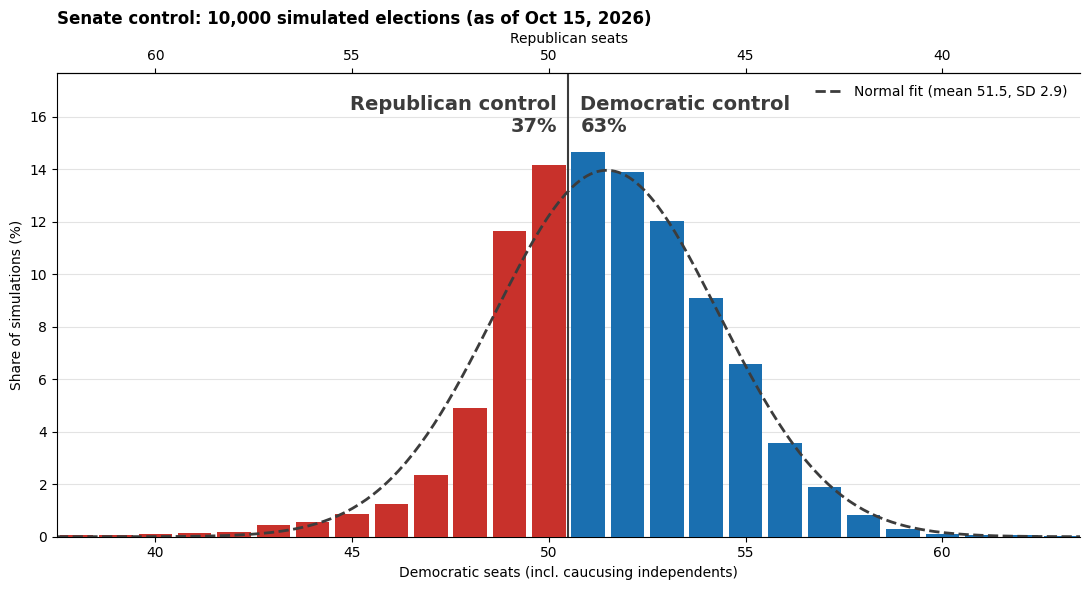

In [16]:
def plot_seat_distribution(d_seats, cfg, today, path=None):
    DEM_BLUE, REP_RED, INK = "#1A6FB0", "#C8312B", "#3C3C3C"
    need = control_threshold(cfg)
    seats, counts = np.unique(d_seats, return_counts=True)              # seat count -> # sims
    pct = 100 * counts / len(d_seats)
    p_dem = (d_seats >= need).mean()
    mu, sd = d_seats.mean(), d_seats.std()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.bar(seats, pct, width=0.85, color=np.where(seats >= need, DEM_BLUE, REP_RED), zorder=3)
    x = np.linspace(seats.min() - 2, seats.max() + 2, 400)
    ax.plot(x, 100 * norm.pdf(x, mu, sd), color=INK, lw=2, ls="--", zorder=4,
            label=f"Normal fit (mean {mu:.1f}, SD {sd:.1f})")             # smooth reference curve
    ax.axvline(need - 0.5, color=INK, lw=1.5, zorder=2)                 # control threshold
    top = pct.max() * 1.15
    ax.text(need - 0.8, top, f"Republican control\n{1 - p_dem:.0%}", ha="right", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.text(need - 0.2, top, f"Democratic control\n{p_dem:.0%}", ha="left", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.set_ylim(0, top * 1.05)
    ax.set_xlim(np.percentile(d_seats, 0.1) - 1.5, np.percentile(d_seats, 99.9) + 1.5)  # trim ultra-rare tails
    ax.set_xlabel("Democratic seats (incl. caucusing independents)")
    ax.set_ylabel("Share of simulations (%)")
    ax.secondary_xaxis("top", functions=(lambda v: 100 - v, lambda v: 100 - v)).set_xlabel("Republican seats")
    ax.grid(axis="y", color="#E3E3E3", zorder=0)                         # recessive grid
    ax.spines[["right"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False)
    ax.set_title(f"Senate control: {len(d_seats):,} simulated elections (as of {today:%b %d, %Y})", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_seat_distribution(RES["d_seats"], CONFIG, RES["today"], CONFIG["OUT_DIR"] / "seat_distribution.png")

### Save outputs
A JSON snapshot of `CONFIG` is saved next to the results so every output can be traced back to the assumptions that produced it.

In [17]:
out = CONFIG["OUT_DIR"]
race_table.to_csv(out / "race_probabilities.csv")
win_table.to_csv(out / "state_win_probabilities.csv")
pd.Series(RES["d_seats"]).value_counts().sort_index().rename("n_sims") \
    .to_csv(out / "seat_distribution.csv", index_label="dem_seats")
snapshot = {k: v for k, v in CONFIG.items() if k != "SWEEP_PARAMS"}    # sweep grid isn't a model assumption
snapshot["STATE_PAIR_CORR_OVERRIDES"] = {f"{a}|{b}": r for (a, b), r in CONFIG["STATE_PAIR_CORR_OVERRIDES"].items()}  # tuple keys -> strings for JSON
with open(out / "config_snapshot.json", "w") as f:
    json.dump(snapshot, f, indent=2, default=str)                       # Paths/timestamps -> strings
print(f"Saved race_probabilities.csv, state_win_probabilities.csv, seat_distribution.csv/.png, config_snapshot.json to {out}")

Saved race_probabilities.csv, state_win_probabilities.csv, seat_distribution.csv/.png, config_snapshot.json to c:\Users\markg\OneDrive\Desktop\DACCS\DACSS 758 - Text As Data\2026_Midterm_Forecast\Output


## Step 10: Sensitivity sweep

Re-runs the model once per value in `SWEEP_PARAMS`, changing **one setting at a time** while everything else stays at its `CONFIG` value. Every run uses the same seed, so differences come from the setting rather than simulation noise. Each run uses `SWEEP_N_SIMS` simulations, so results differ slightly from the main forecast.

To sweep a new assumption, add `"KEY": [values...]` to `SWEEP_PARAMS`. Settings that are dictionaries (e.g. `PARTISAN_HOUSE_EFFECTS`) take whole dictionaries as values.

In [18]:
def value_label(v):
    """Short readable label for a swept value (dicts get compressed)."""
    if isinstance(v, dict):
        return ", ".join(f"{k.split('/')[0][:3]}={x:.2g}" if isinstance(x, (int, float)) else f"{k}={x}" for k, x in v.items())
    return str(v)


def run_sweep(data, cfg):
    rows = []
    base = run_model(data, cfg, n_sims=cfg["SWEEP_N_SIMS"], verbose=False)["summary"]  # baseline at sweep sim count
    for key, values in cfg["SWEEP_PARAMS"].items():
        for v in values:
            c = copy.deepcopy(cfg)                                      # never mutate CONFIG itself
            c[key] = v
            res = run_model(data, c, n_sims=cfg["SWEEP_N_SIMS"], verbose=False)
            row = {"param": key, "value": value_label(v), "is_default": v == cfg[key],
                   **{k: res["summary"][k] for k in ("p_d_control", "mean_d_seats", "env")}}
            for st in cfg["SWEEP_TRACK_STATES"]:
                row[f"P(D) {st}"] = res["races"].loc[st, "p_dem_national_sim"]  # tracked races
            rows.append(row)
    return pd.DataFrame(rows), base


if CONFIG["RUN_SWEEP"]:
    sweep, sweep_base = run_sweep(DATA, CONFIG)
    sweep.to_csv(CONFIG["OUT_DIR"] / "sensitivity_sweep.csv", index=False)
    print(f"{len(sweep)} runs | baseline P(D control) at {CONFIG['SWEEP_N_SIMS']:,} sims = {sweep_base['p_d_control']:.1%}")
    display(sweep.round(3))

64 runs | baseline P(D control) at 3,000 sims = 63.6%


,param,value,is_default,p_d_control,mean_d_seats,env,P(D) Maine,P(D) North Carolina,P(D) Ohio,P(D) Texas,P(D) Iowa,P(D) Alaska,P(D) Michigan,P(D) Nebraska
0,RECENCY_HALF_LIFE_DAYS,7,False,0.613,51.292,7.533,0.922,0.981,0.644,0.572,0.365,0.454,0.886,0.182
1,RECENCY_HALF_LIFE_DAYS,14,False,0.633,51.394,7.533,0.919,0.981,0.651,0.597,0.393,0.497,0.891,0.182
2,RECENCY_HALF_LIFE_DAYS,21,True,0.636,51.416,7.533,0.918,0.981,0.654,0.601,0.405,0.506,0.891,0.183
3,RECENCY_HALF_LIFE_DAYS,30,False,0.638,51.424,7.533,0.917,0.981,0.657,0.603,0.410,0.512,0.891,0.184
4,RECENCY_HALF_LIFE_DAYS,45,False,0.642,51.434,7.533,0.917,0.981,0.658,0.605,0.415,0.519,0.891,0.187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,INDEPENDENT_CAUCUS_PROB_D,Neb=0.5,False,0.635,51.359,7.533,0.918,0.981,0.654,0.601,0.405,0.506,0.891,0.183
60,INDEPENDENT_CAUCUS_PROB_D,Neb=0.8,True,0.636,51.416,7.533,0.918,0.981,0.654,0.601,0.405,0.506,0.891,0.183
61,INDEPENDENT_CAUCUS_PROB_D,Neb=1,False,0.637,51.450,7.533,0.918,0.981,0.654,0.601,0.405,0.506,0.891,0.183
62,D_SEATS_FOR_CONTROL,None,True,0.636,51.416,7.533,0.918,0.981,0.654,0.601,0.405,0.506,0.891,0.183


### Which assumptions move the forecast most?
Each bar spans the lowest to highest P(D control) across that setting's values; the vertical line is the baseline. Longer bar = the forecast depends more on that assumption.

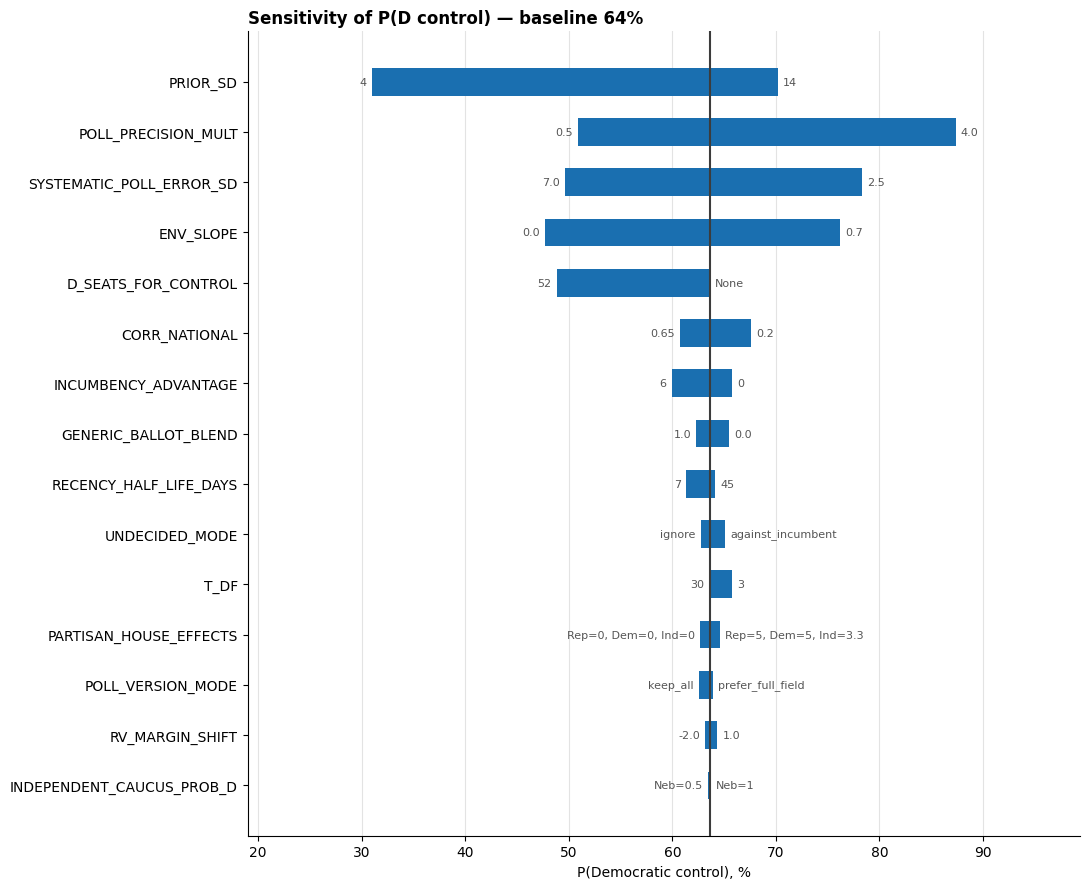

In [19]:
def plot_tornado(sweep, base, path=None):
    rng_ = sweep.groupby("param")["p_d_control"].agg(["min", "max"])     # range per setting
    lo_lab = sweep.loc[sweep.groupby("param")["p_d_control"].idxmin()].set_index("param")["value"]  # value giving the min
    hi_lab = sweep.loc[sweep.groupby("param")["p_d_control"].idxmax()].set_index("param")["value"]  # value giving the max
    rng_ = rng_.assign(span=rng_["max"] - rng_["min"]).sort_values("span")  # biggest effect on top
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(rng_) + 1.5))
    y = np.arange(len(rng_))
    ax.barh(y, 100 * rng_["span"], left=100 * rng_["min"], height=0.55, color="#1A6FB0", zorder=3)
    ax.axvline(100 * base["p_d_control"], color="#3C3C3C", lw=1.5, zorder=4)  # baseline
    for i, (param, r) in enumerate(rng_.iterrows()):
        ax.text(100 * r["min"] - 0.5, i, lo_lab[param], ha="right", va="center", fontsize=8, color="#555555")
        ax.text(100 * r["max"] + 0.5, i, hi_lab[param], ha="left", va="center", fontsize=8, color="#555555")
    ax.set_yticks(y, rng_.index)
    ax.set_xlabel("P(Democratic control), %")
    ax.grid(axis="x", color="#E3E3E3", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_title(f"Sensitivity of P(D control) — baseline {base['p_d_control']:.0%}", loc="left", fontweight="bold")
    lo, hi = 100 * rng_["min"].min(), 100 * rng_["max"].max()
    ax.set_xlim(max(0, lo - 12), min(100, hi + 12))                      # room for value labels
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


if CONFIG["RUN_SWEEP"]:
    plot_tornado(sweep, sweep_base, CONFIG["OUT_DIR"] / "sensitivity_tornado.png")

### Each setting, value by value
One panel per swept setting; the filled marker is the current `CONFIG` value.

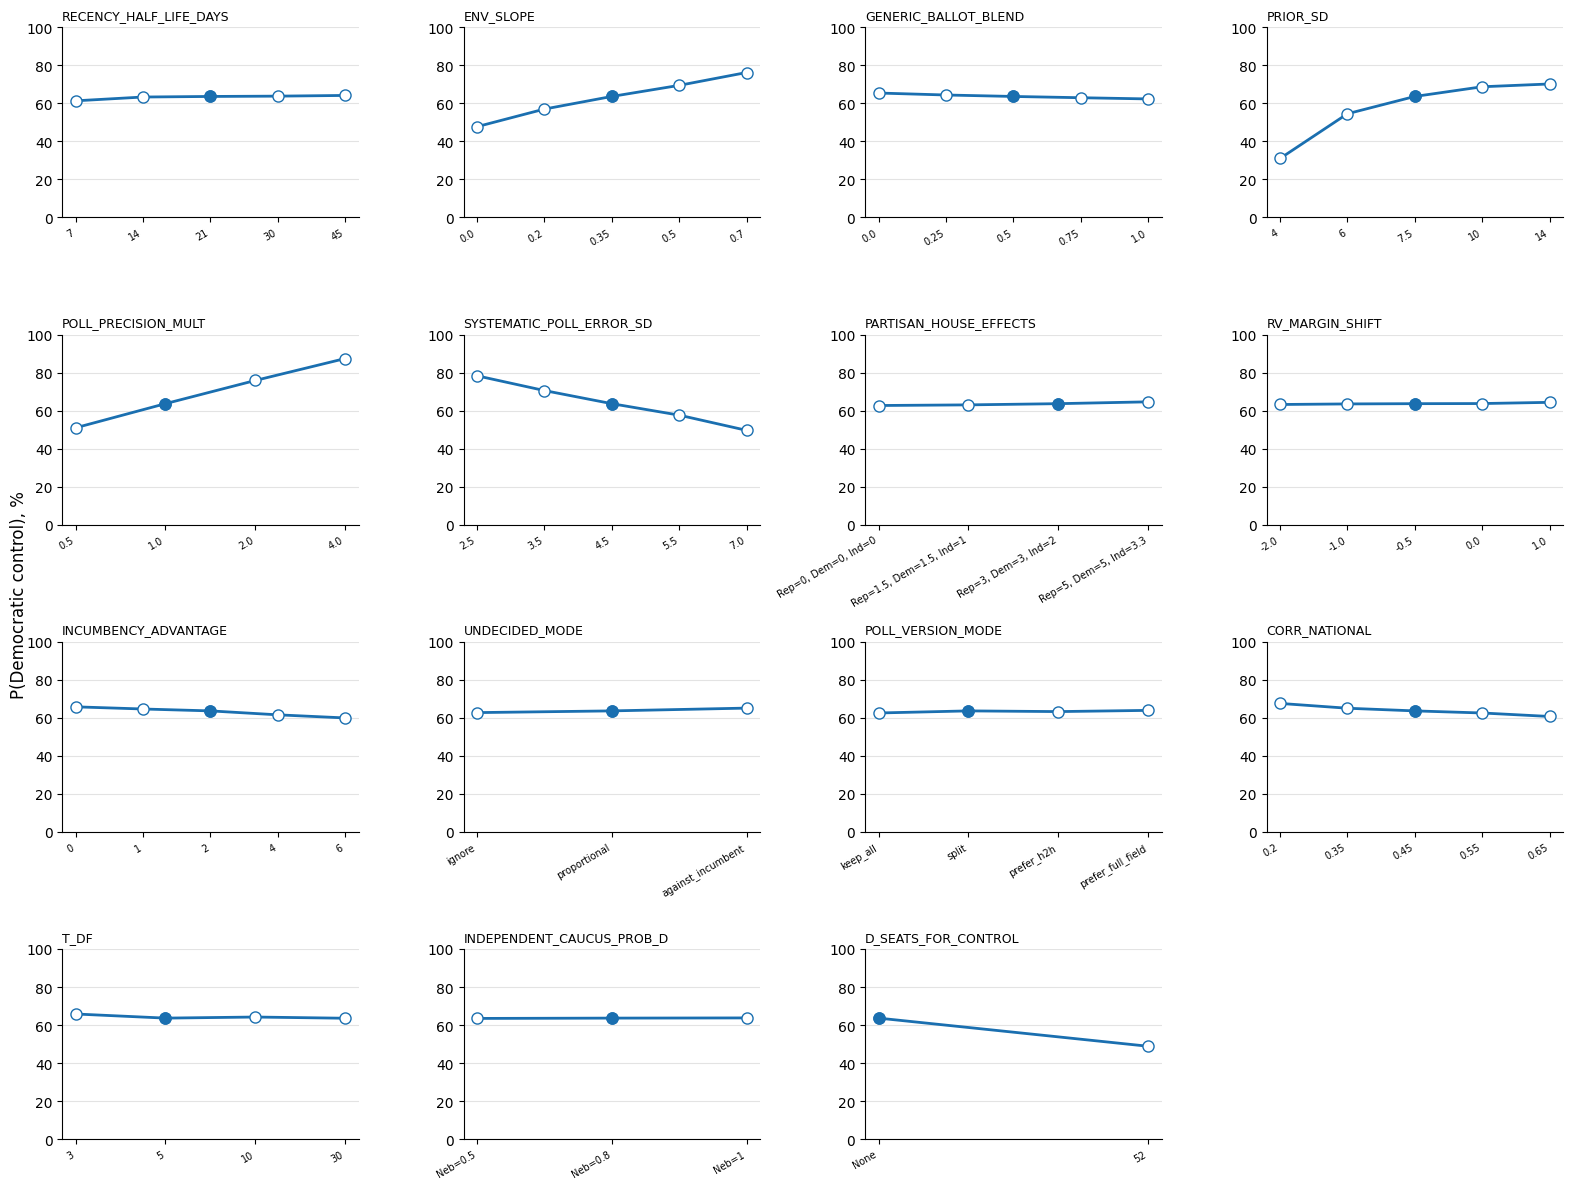

In [20]:
def plot_sweep_panels(sweep, cols=4):
    params = list(dict.fromkeys(sweep["param"]))                         # keep CONFIG order
    rows = int(np.ceil(len(params) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows), squeeze=False)
    for ax, param in zip(axes.flat, params):
        s = sweep[sweep["param"] == param].reset_index(drop=True)
        x = np.arange(len(s))                                           # categorical positions (works for text values)
        ax.plot(x, 100 * s["p_d_control"], color="#1A6FB0", lw=2, marker="o", ms=8, mfc="white", zorder=3)
        d = s.index[s["is_default"]]
        ax.plot(d, 100 * s.loc[d, "p_d_control"], "o", color="#1A6FB0", ms=8, zorder=4)  # filled = default
        ax.set_xticks(x, s["value"], rotation=30, ha="right", fontsize=7)
        ax.set_title(param, fontsize=9, loc="left")
        ax.set_ylim(0, 100)
        ax.grid(axis="y", color="#E3E3E3", zorder=0)
        ax.spines[["right", "top"]].set_visible(False)
    for ax in list(axes.flat)[len(params):]:
        ax.set_visible(False)                                           # hide unused panels
    fig.supylabel("P(Democratic control), %")
    fig.tight_layout()
    plt.show()


if CONFIG["RUN_SWEEP"]:
    plot_sweep_panels(sweep)

### Which races are most assumption-sensitive?
For each setting, the spread (max − min) of each tracked state's P(D win) across the values tried. Large numbers flag races where the team's choices matter most.

In [21]:
if CONFIG["RUN_SWEEP"]:
    state_cols = [c for c in sweep.columns if c.startswith("P(D) ")]
    spread = sweep.groupby("param")[state_cols].agg(lambda x: x.max() - x.min())  # range per setting × state
    spread.columns = [c.replace("P(D) ", "") for c in state_cols]
    display(spread.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None))

,Maine,North Carolina,Ohio,Texas,Iowa,Alaska,Michigan,Nebraska
param,,,,,,,,
CORR_NATIONAL,0%,1%,1%,1%,0%,1%,0%,1%
D_SEATS_FOR_CONTROL,0%,0%,0%,0%,0%,0%,0%,0%
ENV_SLOPE,7%,2%,25%,25%,26%,27%,10%,11%
GENERIC_BALLOT_BLEND,1%,0%,3%,3%,3%,3%,1%,1%
INCUMBENCY_ADVANTAGE,6%,0%,0%,0%,0%,21%,0%,8%
INDEPENDENT_CAUCUS_PROB_D,0%,0%,0%,0%,0%,0%,0%,0%
PARTISAN_HOUSE_EFFECTS,1%,0%,1%,5%,1%,2%,0%,4%
POLL_PRECISION_MULT,3%,5%,38%,40%,22%,45%,6%,15%
POLL_VERSION_MODE,0%,0%,3%,0%,0%,3%,0%,2%
